# Phase 6: Machine Learning Models for Gene Expression Classification

### Overview
This notebook trains and benchmarks machine learning models on the consensus 67-biomarker gene signature selected in Phase 4:
- **Models Evaluated**: Random Forest, XGBoost, and Multi-Layer Perceptron (MLP).
- **Validation**: 5-Fold Stratified Cross-Validation + Isolated Test Set (20%).
- **Key Metrics**: Accuracy, Balanced Accuracy, Macro AUROC, Matthews Correlation Coefficient (MCC).
- **Artefacts Saved**: Trained models (`models/gene_*.pkl`), Scaler (`models/gene_scaler.pkl`), Label Encoder, and Feature Metadata.


In [1]:
import os
import sys
import json
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display
import joblib

sys.path.append("C:/Research_Project/Brain_Tumor_Project")
from src.gene_model import (
    run_gene_training_pipeline, load_gene_data,
    plot_gene_confusion_matrix, plot_gene_comparison_bar,
    load_gene_artefacts, predict_gene, ensemble_gene_predict,
    RESULTS_DIR, MODELS_DIR
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
print("Environment and modules successfully loaded.")


Environment and modules successfully loaded.


## 1. Train Gene ML Models (Random Forest, XGBoost, MLP)

In [2]:
results = run_gene_training_pipeline(test_size=0.2, save_models=True)

print("\n=== GENE MODEL BENCHMARK RESULTS ===")
for name, m in results.items():
    acc  = m['accuracy']
    bacc = m['balanced_accuracy']
    auroc = m['auroc']
    mcc   = m['mcc']
    cv    = m['cv_mean']
    print(f"  {name:15s} | Acc: {acc:.4f} | Balanced Acc: {bacc:.4f} | AUROC: {auroc:.4f} | MCC: {mcc:.4f} | 5-Fold CV: {cv:.4f}")



=== GENE MODEL BENCHMARK RESULTS ===
  RandomForest    | Acc: 1.0000 | Balanced Acc: 1.0000 | AUROC: 1.0000 | MCC: 1.0000 | 5-Fold CV: 1.0000
  MLP             | Acc: 0.9645 | Balanced Acc: 0.9286 | AUROC: 0.9935 | MCC: 0.9047 | 5-Fold CV: 0.8676
  XGBoost         | Acc: 1.0000 | Balanced Acc: 1.0000 | AUROC: 1.0000 | MCC: 1.0000 | 5-Fold CV: 1.0000


## 2. Model Performance Benchmark Comparison Table

In [3]:
comp_df = pd.DataFrame.from_dict(results, orient='index')
comp_csv = RESULTS_DIR / "gene_model_comparison.csv"
comp_df.to_csv(comp_csv)
print(f"Saved comparison to {comp_csv}")
comp_df


Saved comparison to C:\Research_Project\Brain_Tumor_Project\results\gene_model\gene_model_comparison.csv


,accuracy,balanced_accuracy,mcc,kappa,auroc,auprc,report,cv_mean,cv_std
RandomForest,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,"{'GBM': {'precision': 1.0, 'recall': 1.0, 'f1-...",1.0000,0.0000
MLP,0.9645,0.9286,0.9047,0.9002,0.9935,0.9978,"{'GBM': {'precision': 1.0, 'recall': 0.8571428...",0.8676,0.0295
XGBoost,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,"{'GBM': {'precision': 1.0, 'recall': 1.0, 'f1-...",1.0000,0.0000


## 3. Comparative Performance Visualization

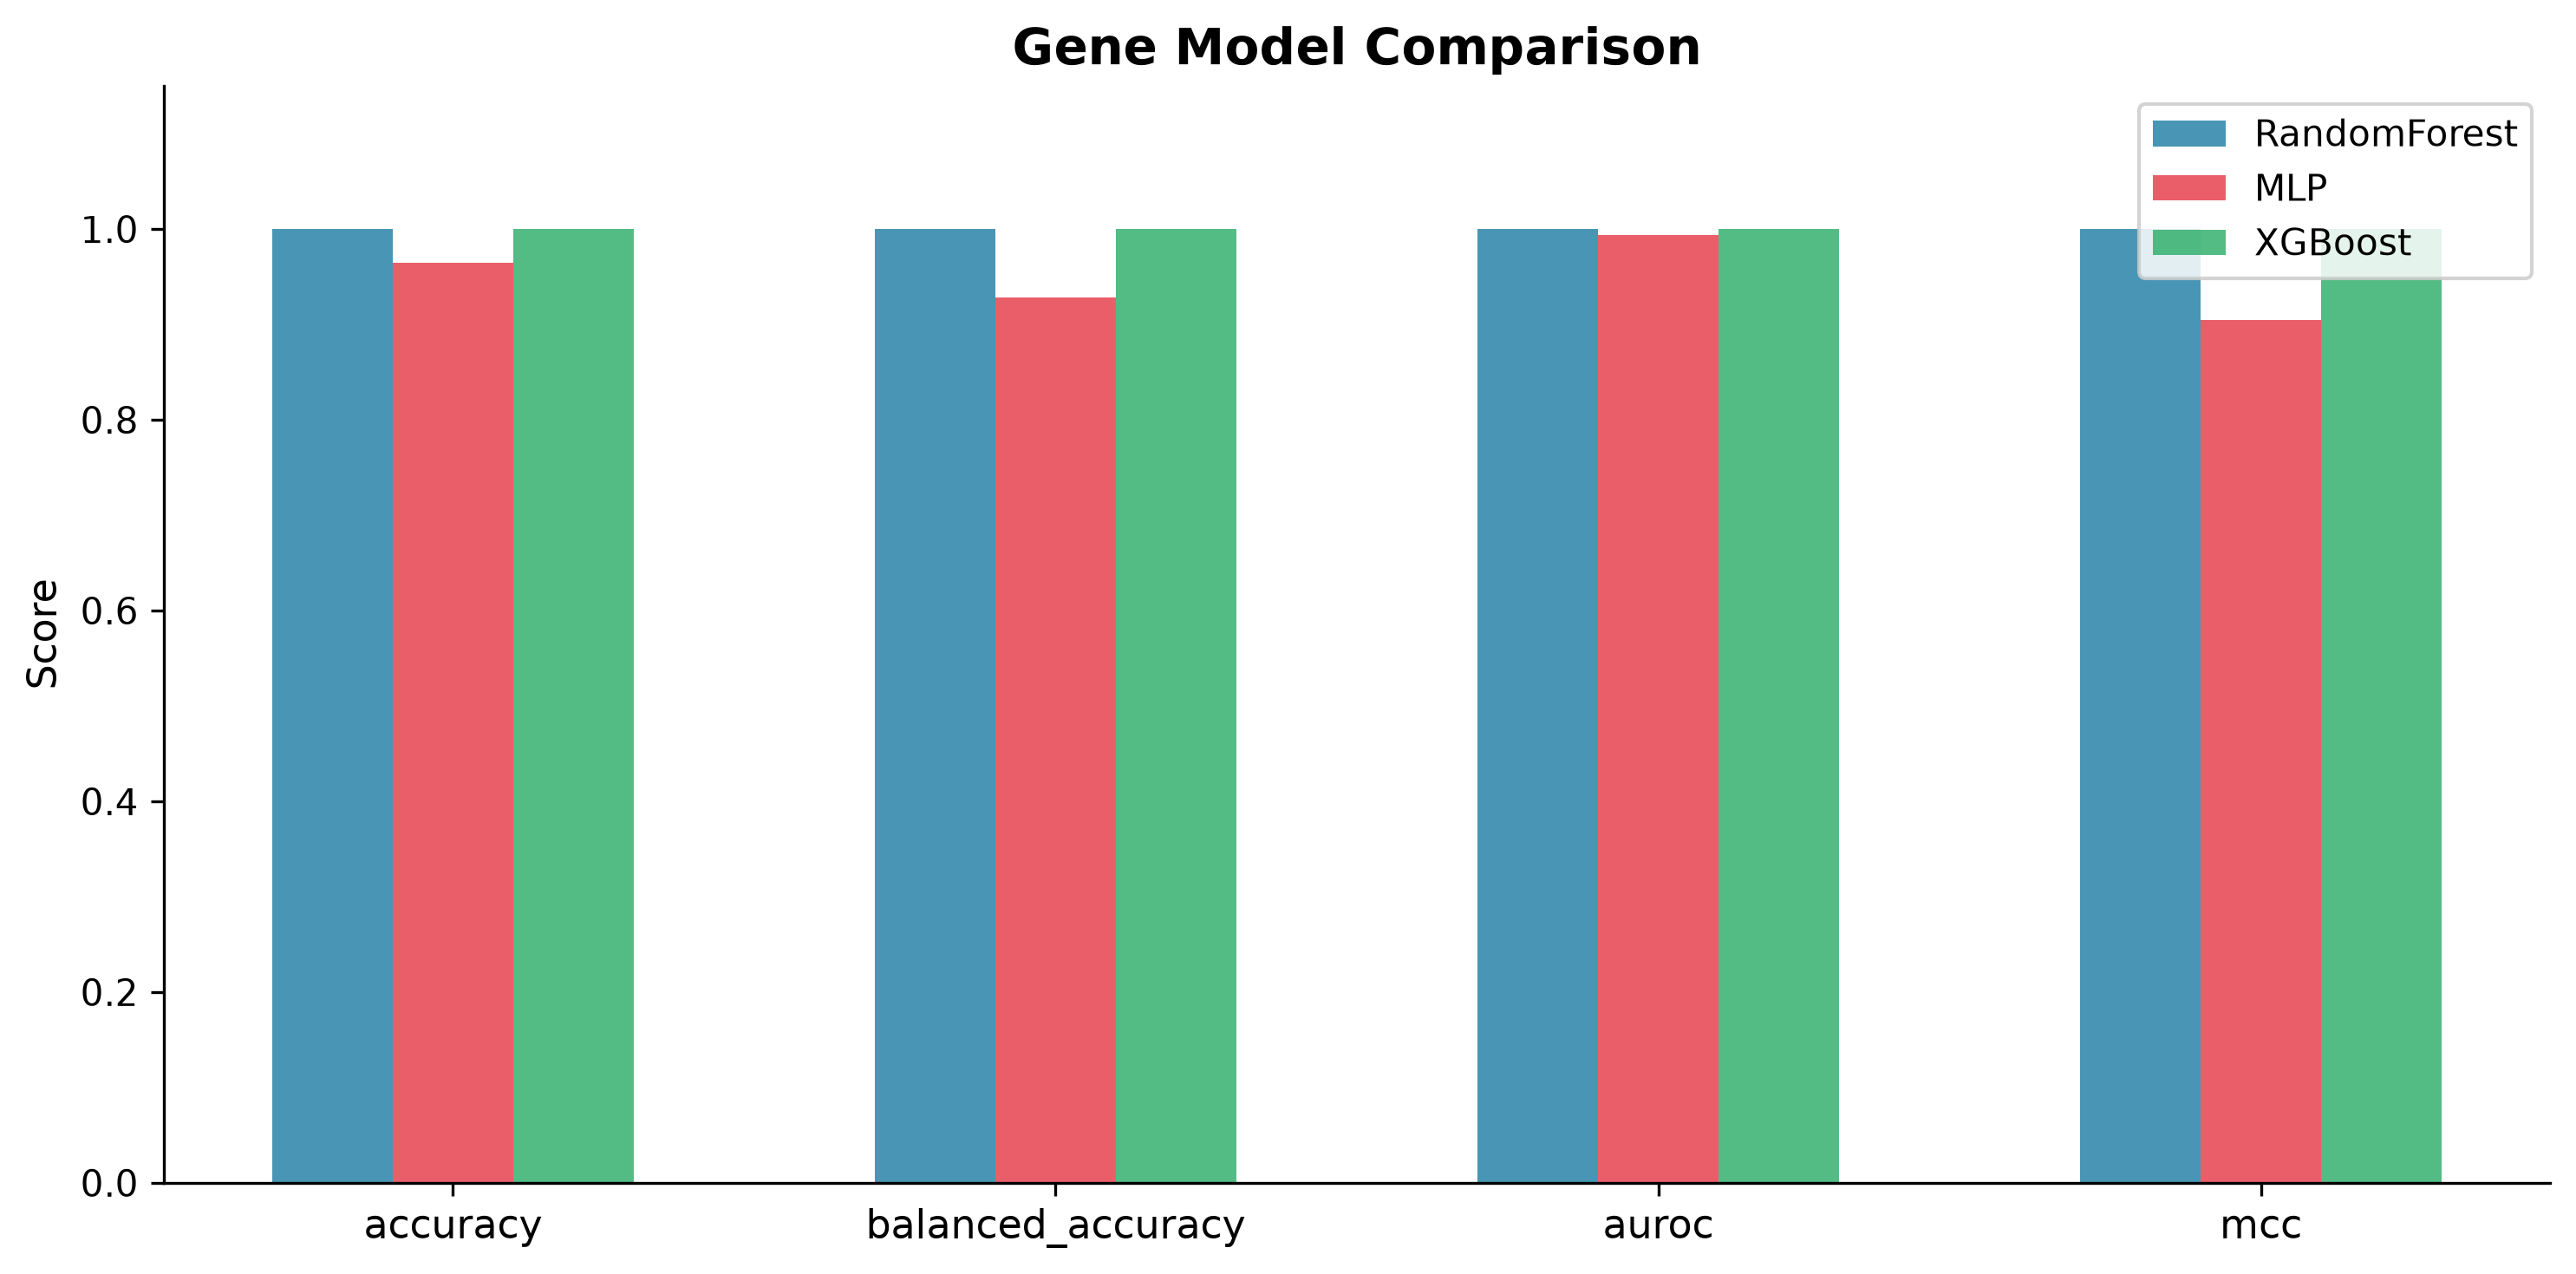

In [4]:
plot_gene_comparison_bar(results, out_dir=RESULTS_DIR)
display(Image(filename=str(RESULTS_DIR / "gene_model_comparison.png")))


## 4. Test Set Confusion Matrices

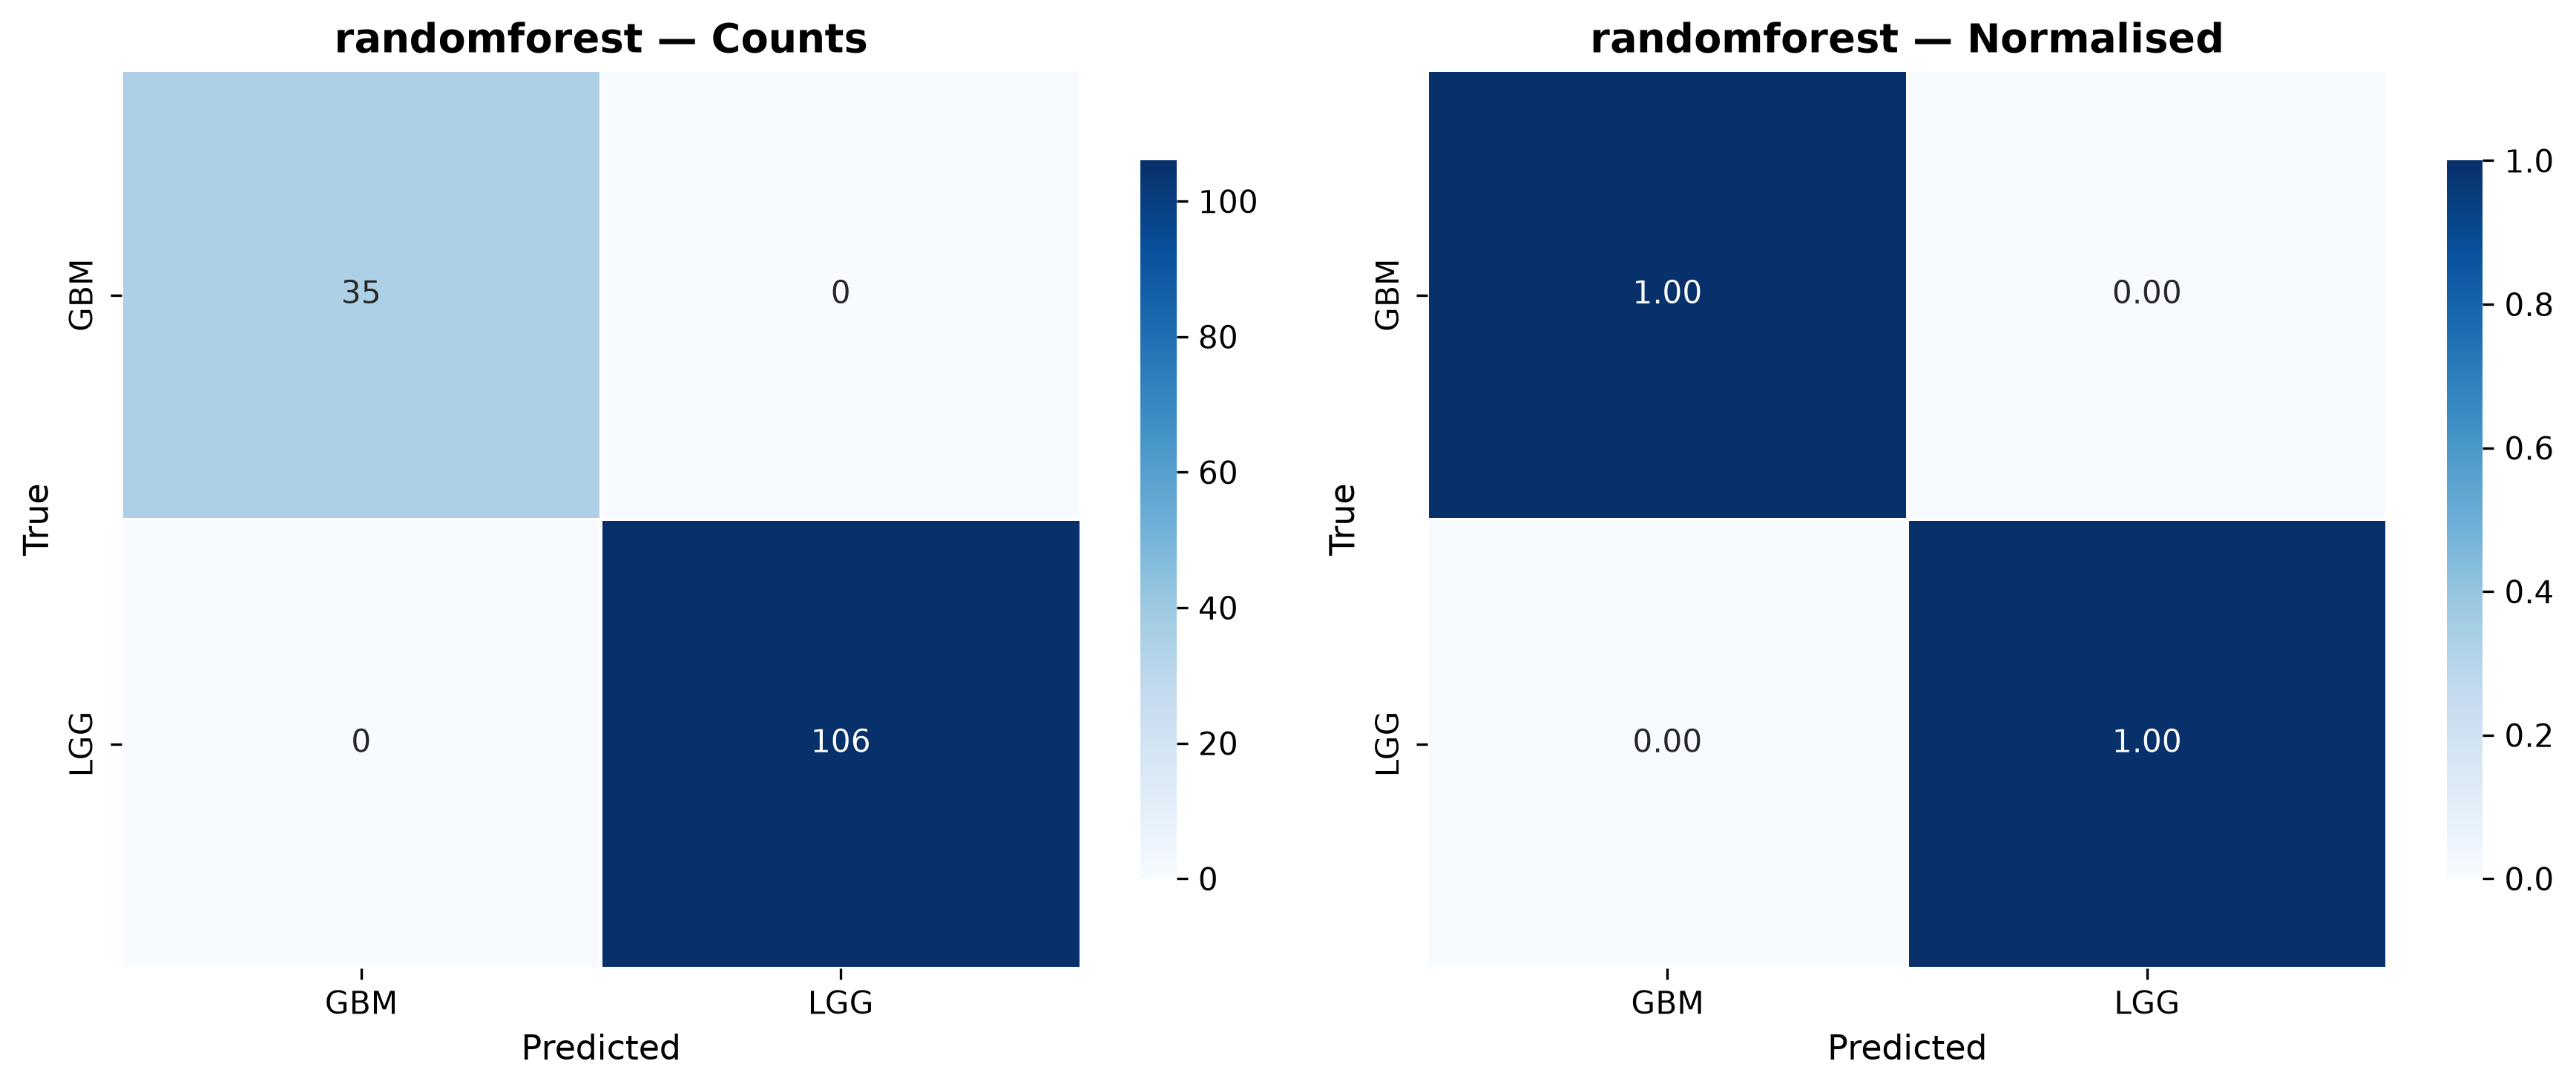

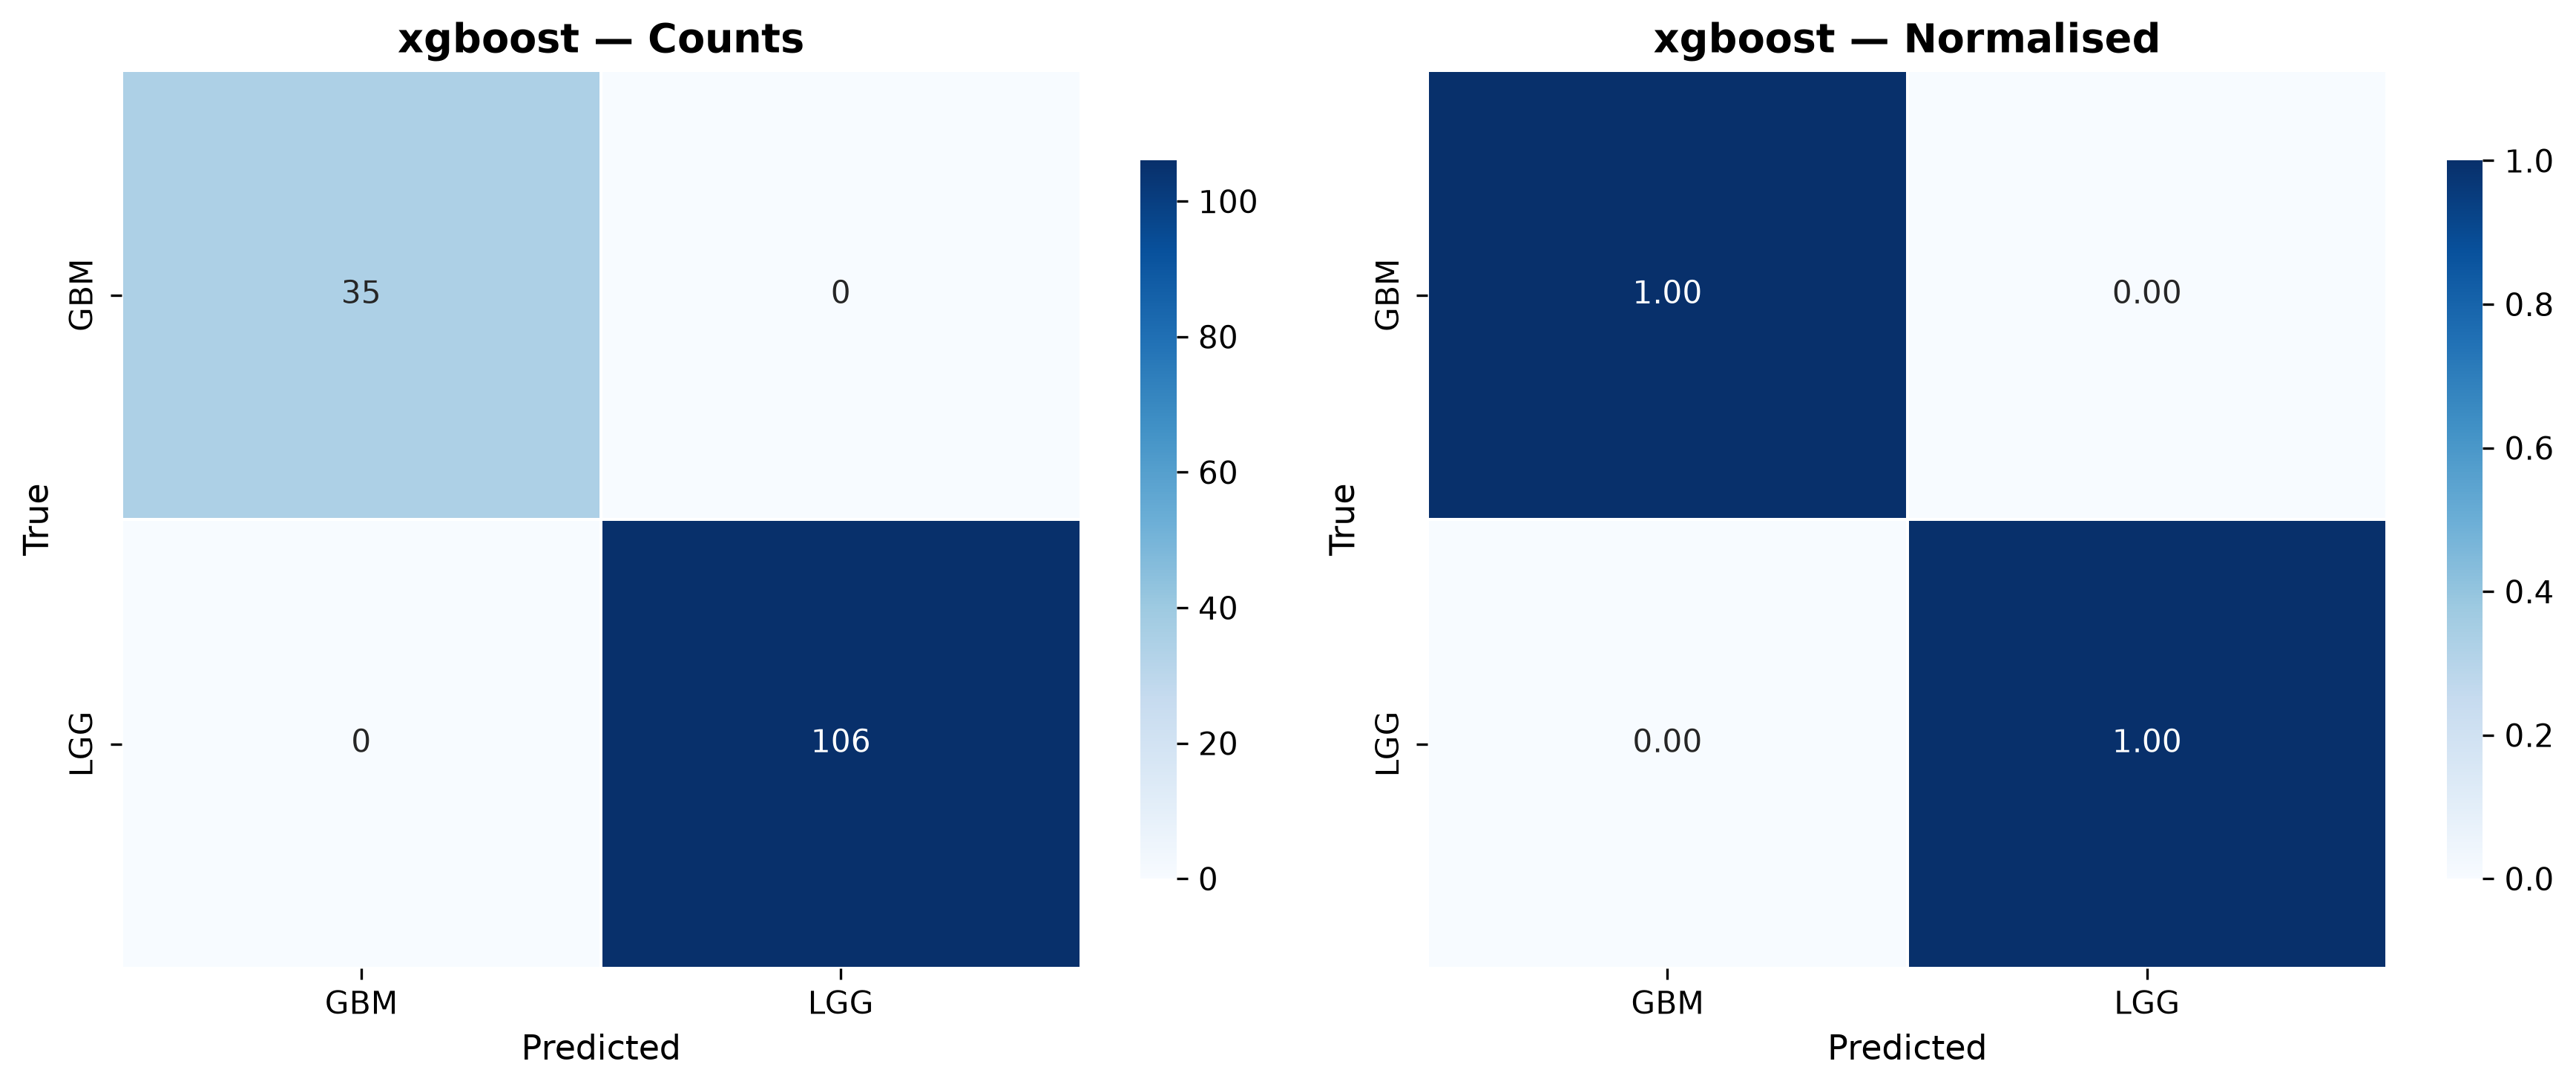

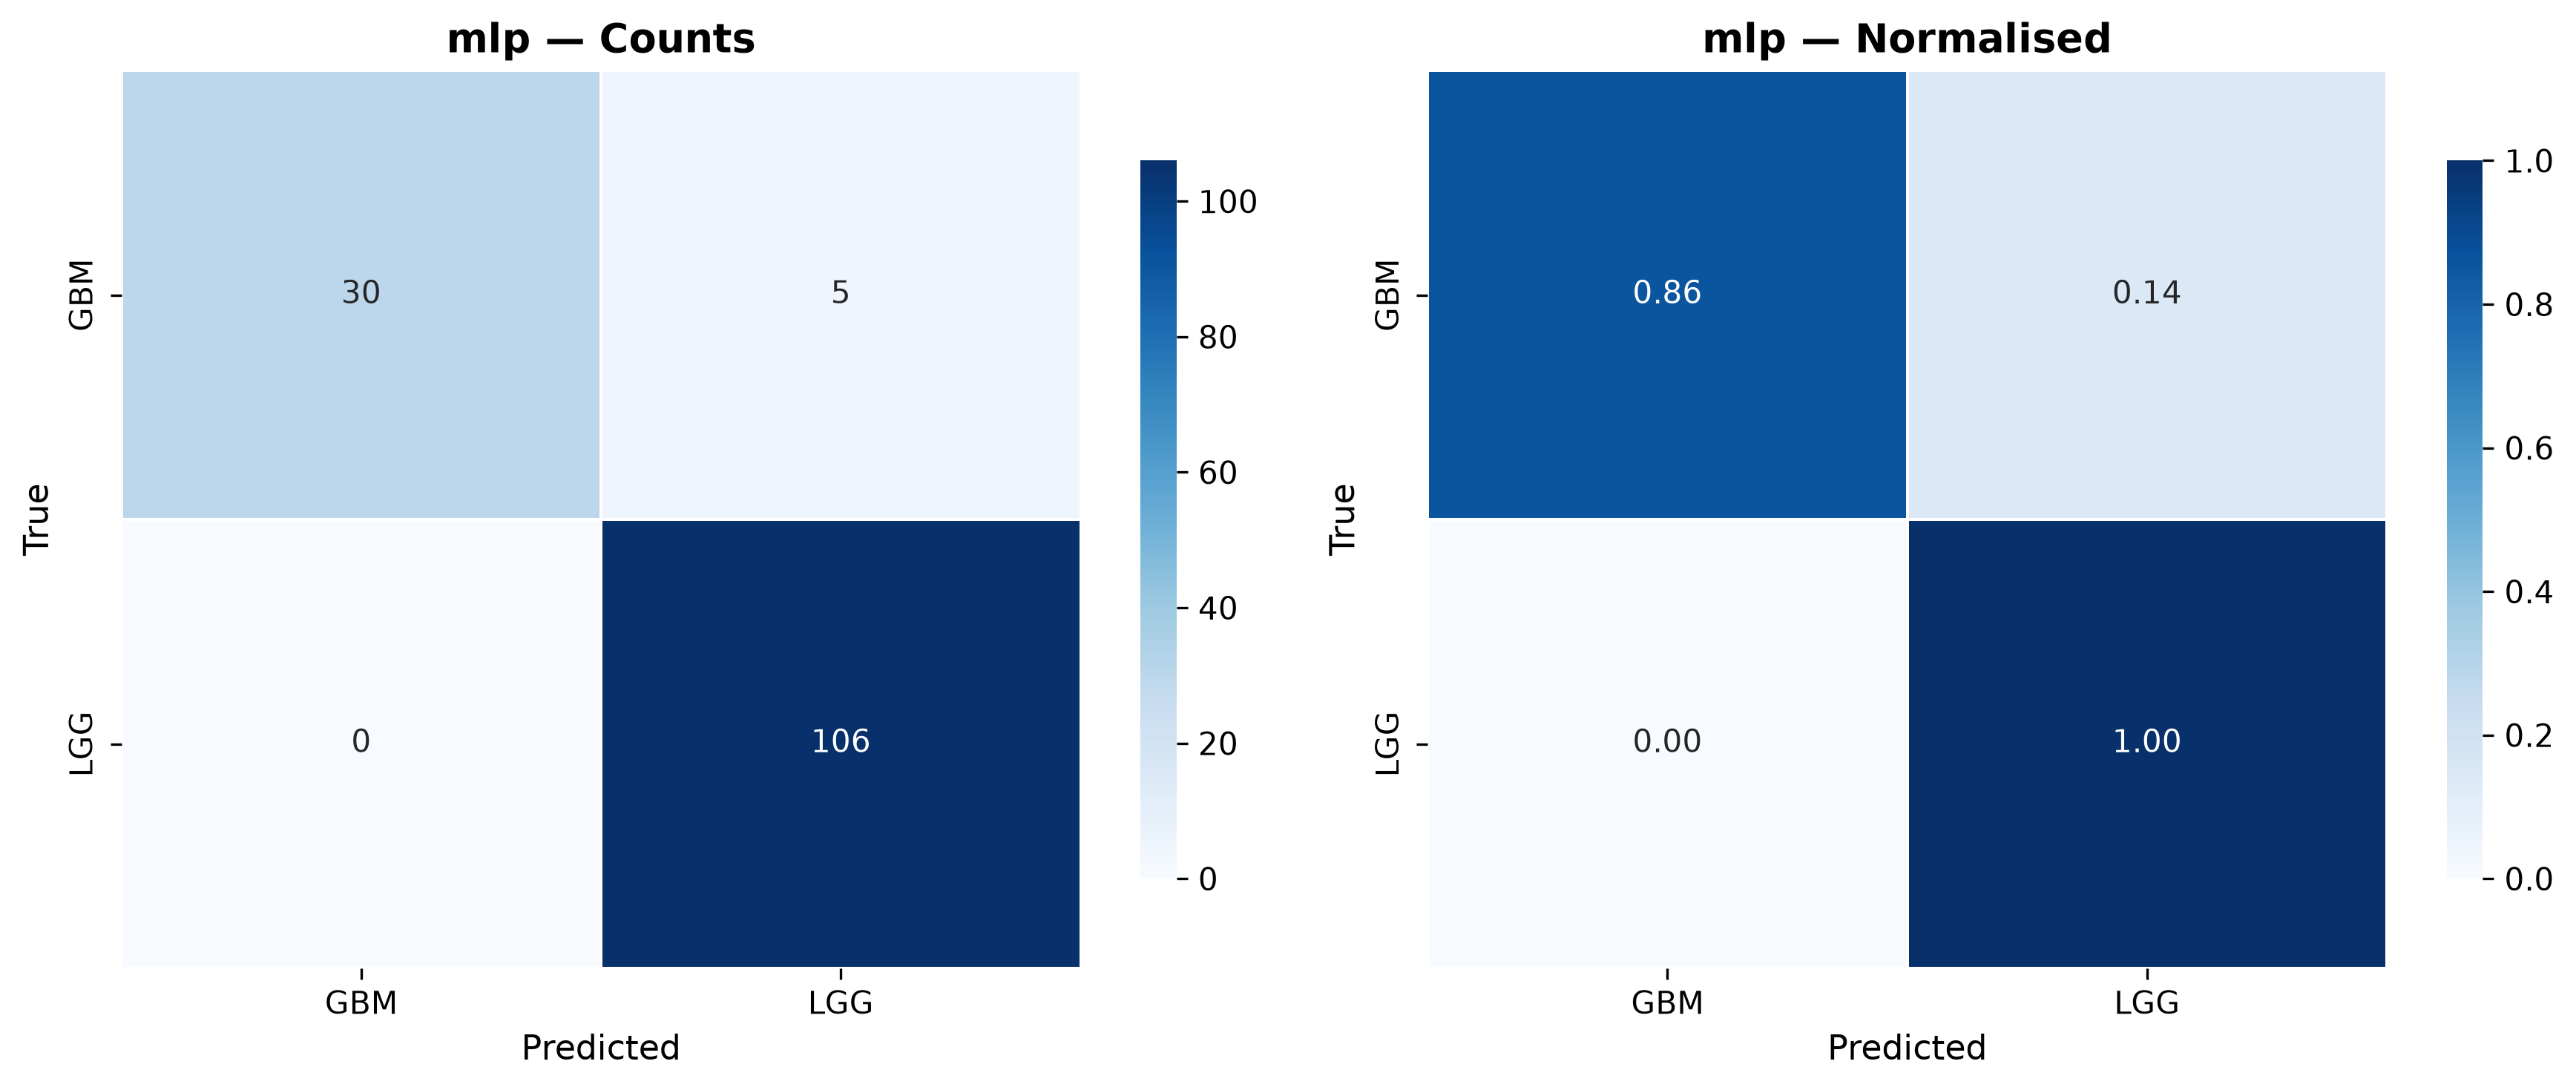

In [5]:
X, y, genes, le = load_gene_data()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
scaler = joblib.load(MODELS_DIR / "gene_scaler.pkl")
X_test_s = scaler.transform(X_test)

for candidate in ['randomforest', 'xgboost', 'mlp']:
    p = MODELS_DIR / f"gene_{candidate}.pkl"
    if p.exists():
        clf = joblib.load(p)
        Xte = X_test_s if candidate == 'mlp' else X_test
        y_pred = clf.predict(Xte)
        plot_gene_confusion_matrix(y_test, y_pred, list(le.classes_), candidate, out_dir=RESULTS_DIR)
        cm_img = RESULTS_DIR / f"gene_{candidate}_confusion_matrix.png"
        if cm_img.exists():
            display(Image(filename=str(cm_img)))


## 5. Saved Model Artefacts Audit

In [6]:
print("Saved Gene Model Artefacts in models/:")
for f in sorted(MODELS_DIR.glob("gene_*.*")):
    print(f"  {f.name:30s} ({f.stat().st_size:,} bytes)")


Saved Gene Model Artefacts in models/:
  gene_feature_names.json        (700 bytes)
  gene_label_encoder.pkl         (485 bytes)
  gene_mlp.pkl                   (715,521 bytes)
  gene_randomforest.pkl          (409,369 bytes)
  gene_scaler.pkl                (2,215 bytes)
  gene_xgboost.pkl               (293,825 bytes)
